In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys

sys.path.append("..")

import json
from pathlib import Path

import dask
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import xarray as xr

sns.set_style("whitegrid", {"grid.color": ".93"})

from src.bias_correction import BiasCorrectionValidation
from src.load_data import ClimateModelData, ClimateReanalysisData
from src.utils_xarray import (
    get_specific_hourly_data,
    get_time_resolution,
    get_valid_hours,
)

In [3]:
paths = json.load(open("../paths.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_figs = Path(paths["path_figs"])

In [ ]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
reference_period = ("1991", "2020")
future_period = (("2021", "2100"),)

In [5]:
validation = BiasCorrectionValidation(reference_period, future_period)

In [6]:
dask.config.set(num_workers=8, scheduler="processes", memory_limit="50 GiB")

In [ ]:
bias_corrected_chunks = {
    "time": 2920,
    "lat": 128,
    "lon": 128,
}

regridded_chunks = {"time": -1, "lat": 20, "lon": 20}

In [8]:
COLORBLIND_PALETTE = sns.color_palette("colorblind")
sns.set_palette(COLORBLIND_PALETTE)

# CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85

## tas

In [ ]:
stats_tas_path = (
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "validation"
    / "3hr"
    / "tas"
)

### Load data

In [ ]:
ds_tas = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "regridded"
    / "3hr"
    / "tas.zarr",
    extent=extent,
    chunks=regridded_chunks,
)

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [ ]:
ds_tas_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "bias_corrected"
    / "3hr"
    / "tas.zarr",
    extent=extent,
    chunks=bias_corrected_chunks,
)

In [ ]:
ds_2t = ClimateReanalysisData(
    path_data_processed / "cerra_processed" / "regridded" / "2t.zarr",
    extent=extent,
    chunks=regridded_chunks,
    load=False,
)
ds_2t.ds_data = ds_2t.ds_data.sel(time=slice(*reference_period))

In [13]:
first_time_step = pd.to_datetime(ds_tas.ds_data.time.values[0])
time_res = get_time_resolution(ds_2t.ds_data)

### Validation plots

In [14]:
ds_yearly_mean = xr.open_dataset(stats_tas_path / "yearly_spatial_mean.nc")

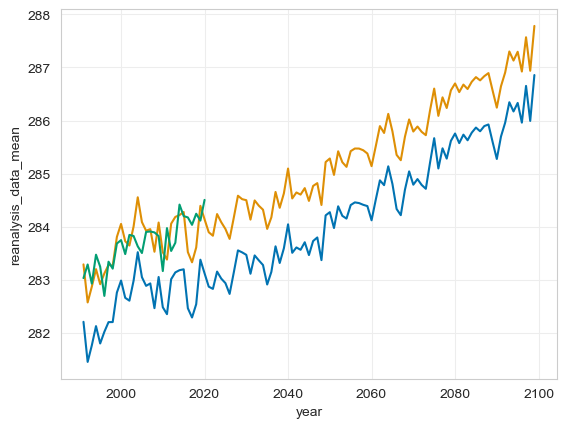

In [15]:
ds_yearly_mean.climate_model_data_mean.plot()
ds_yearly_mean.climate_model_data_bc_mean.plot()
ds_yearly_mean.reanalysis_data_mean.sel(year=slice(*reference_period)).plot()
plt.show()

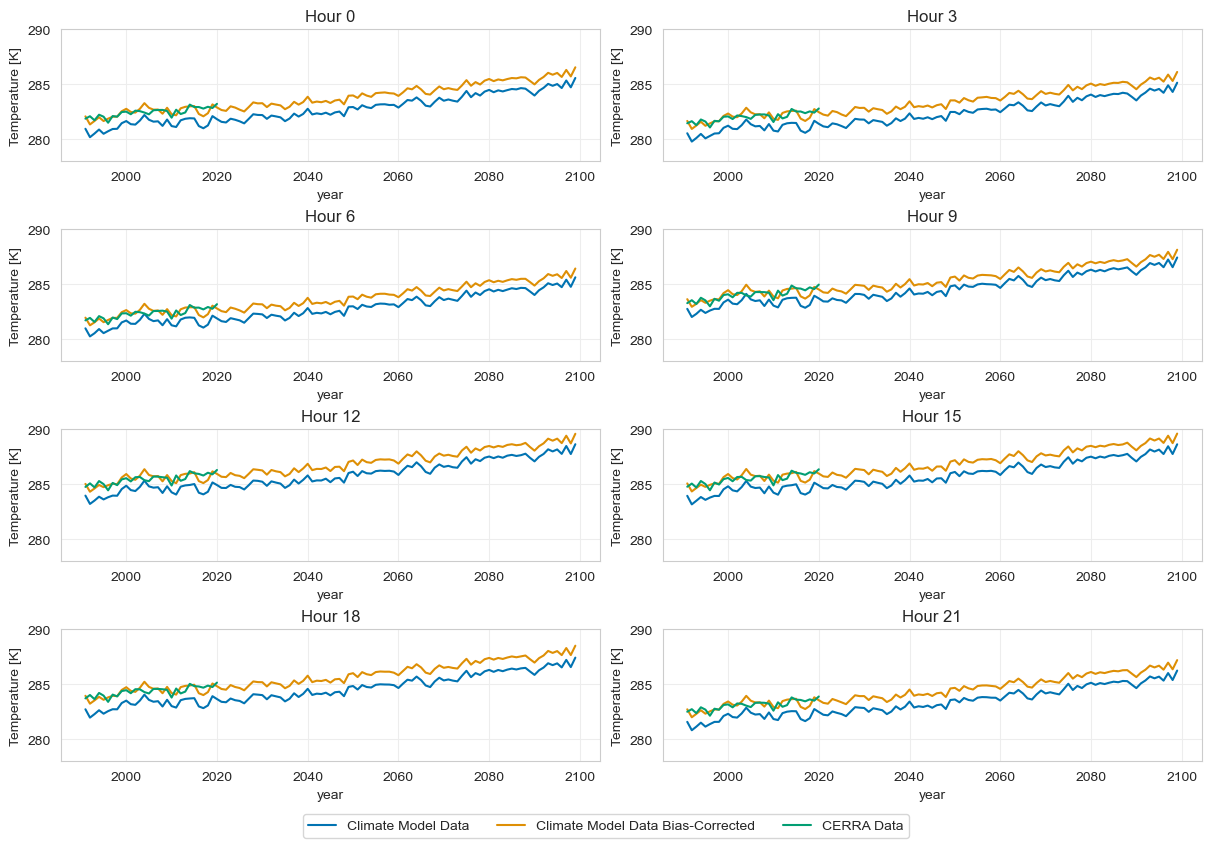

In [ ]:
# Compute the overall min and max over all the datasets
overall_min = float("inf")
overall_max = float("-inf")

fig, axs = plt.subplots(4, 2, figsize=(12, 8), layout="constrained")
axs = axs.flatten()

for i, hour in enumerate(get_valid_hours(time_res, first_time_step.hour)):
    ds_hourly_mean = xr.open_dataset(
        stats_tas_path / f"yearly_spatial_mean_hour_{hour}.nc"
    )
    ds_hourly_mean.climate_model_data_mean.plot(ax=axs[i], label="Climate Model Data")
    ds_hourly_mean.climate_model_data_bc_mean.plot(
        ax=axs[i], label="Climate Model Data Bias-Corrected"
    )
    ds_hourly_mean.reanalysis_data_mean.sel(year=slice(*reference_period)).plot(
        ax=axs[i], label="CERRA Data"
    )

    overall_min = min(
        overall_min,
        ds_hourly_mean.climate_model_data_mean.min().item(),
        ds_hourly_mean.climate_model_data_bc_mean.min().item(),
        ds_hourly_mean.reanalysis_data_mean.min().item(),
    )
    overall_max = max(
        overall_max,
        ds_hourly_mean.climate_model_data_mean.max().item(),
        ds_hourly_mean.climate_model_data_bc_mean.max().item(),
        ds_hourly_mean.reanalysis_data_mean.max().item(),
    )
    axs[i].set_ylabel("Temperature [K]")
    axs[i].set_title(f"Hour {hour}")

for ax in axs:
    ax.set_ylim(int(overall_min) - 1, int(overall_max) + 1)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.05))
plt.show()

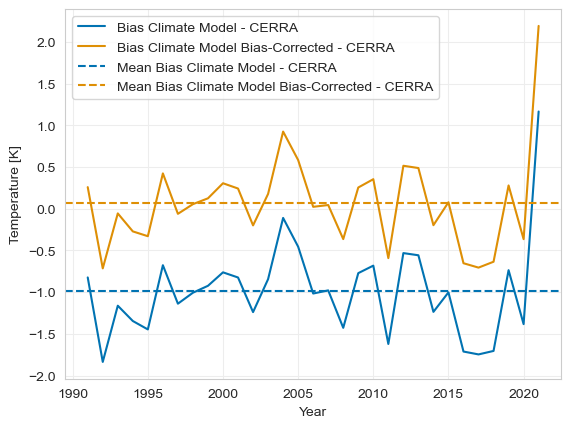

In [ ]:
bias, bias_bc = validation.compute_bias(
    ds_yearly_mean["climate_model_data_mean"],
    ds_yearly_mean["climate_model_data_bc_mean"],
    ds_yearly_mean["reanalysis_data_mean"],
    hour=None,
    group=None,
    period=None,
)

fig, ax = plt.subplots()
bias.plot(label="Bias Climate Model - CERRA", color=COLORBLIND_PALETTE[0])
bias_bc.plot(
    label="Bias Climate Model Bias-Corrected - CERRA", color=COLORBLIND_PALETTE[1]
)
ax.axhline(
    bias.mean(),
    color=COLORBLIND_PALETTE[0],
    linestyle="--",
    label="Mean Bias Climate Model - CERRA",
)
ax.axhline(
    bias_bc.mean(),
    color=COLORBLIND_PALETTE[1],
    linestyle="--",
    label="Mean Bias Climate Model Bias-Corrected - CERRA",
)
plt.ylabel("Temperature [K]")
plt.xlabel("Year")
plt.legend()
plt.show()

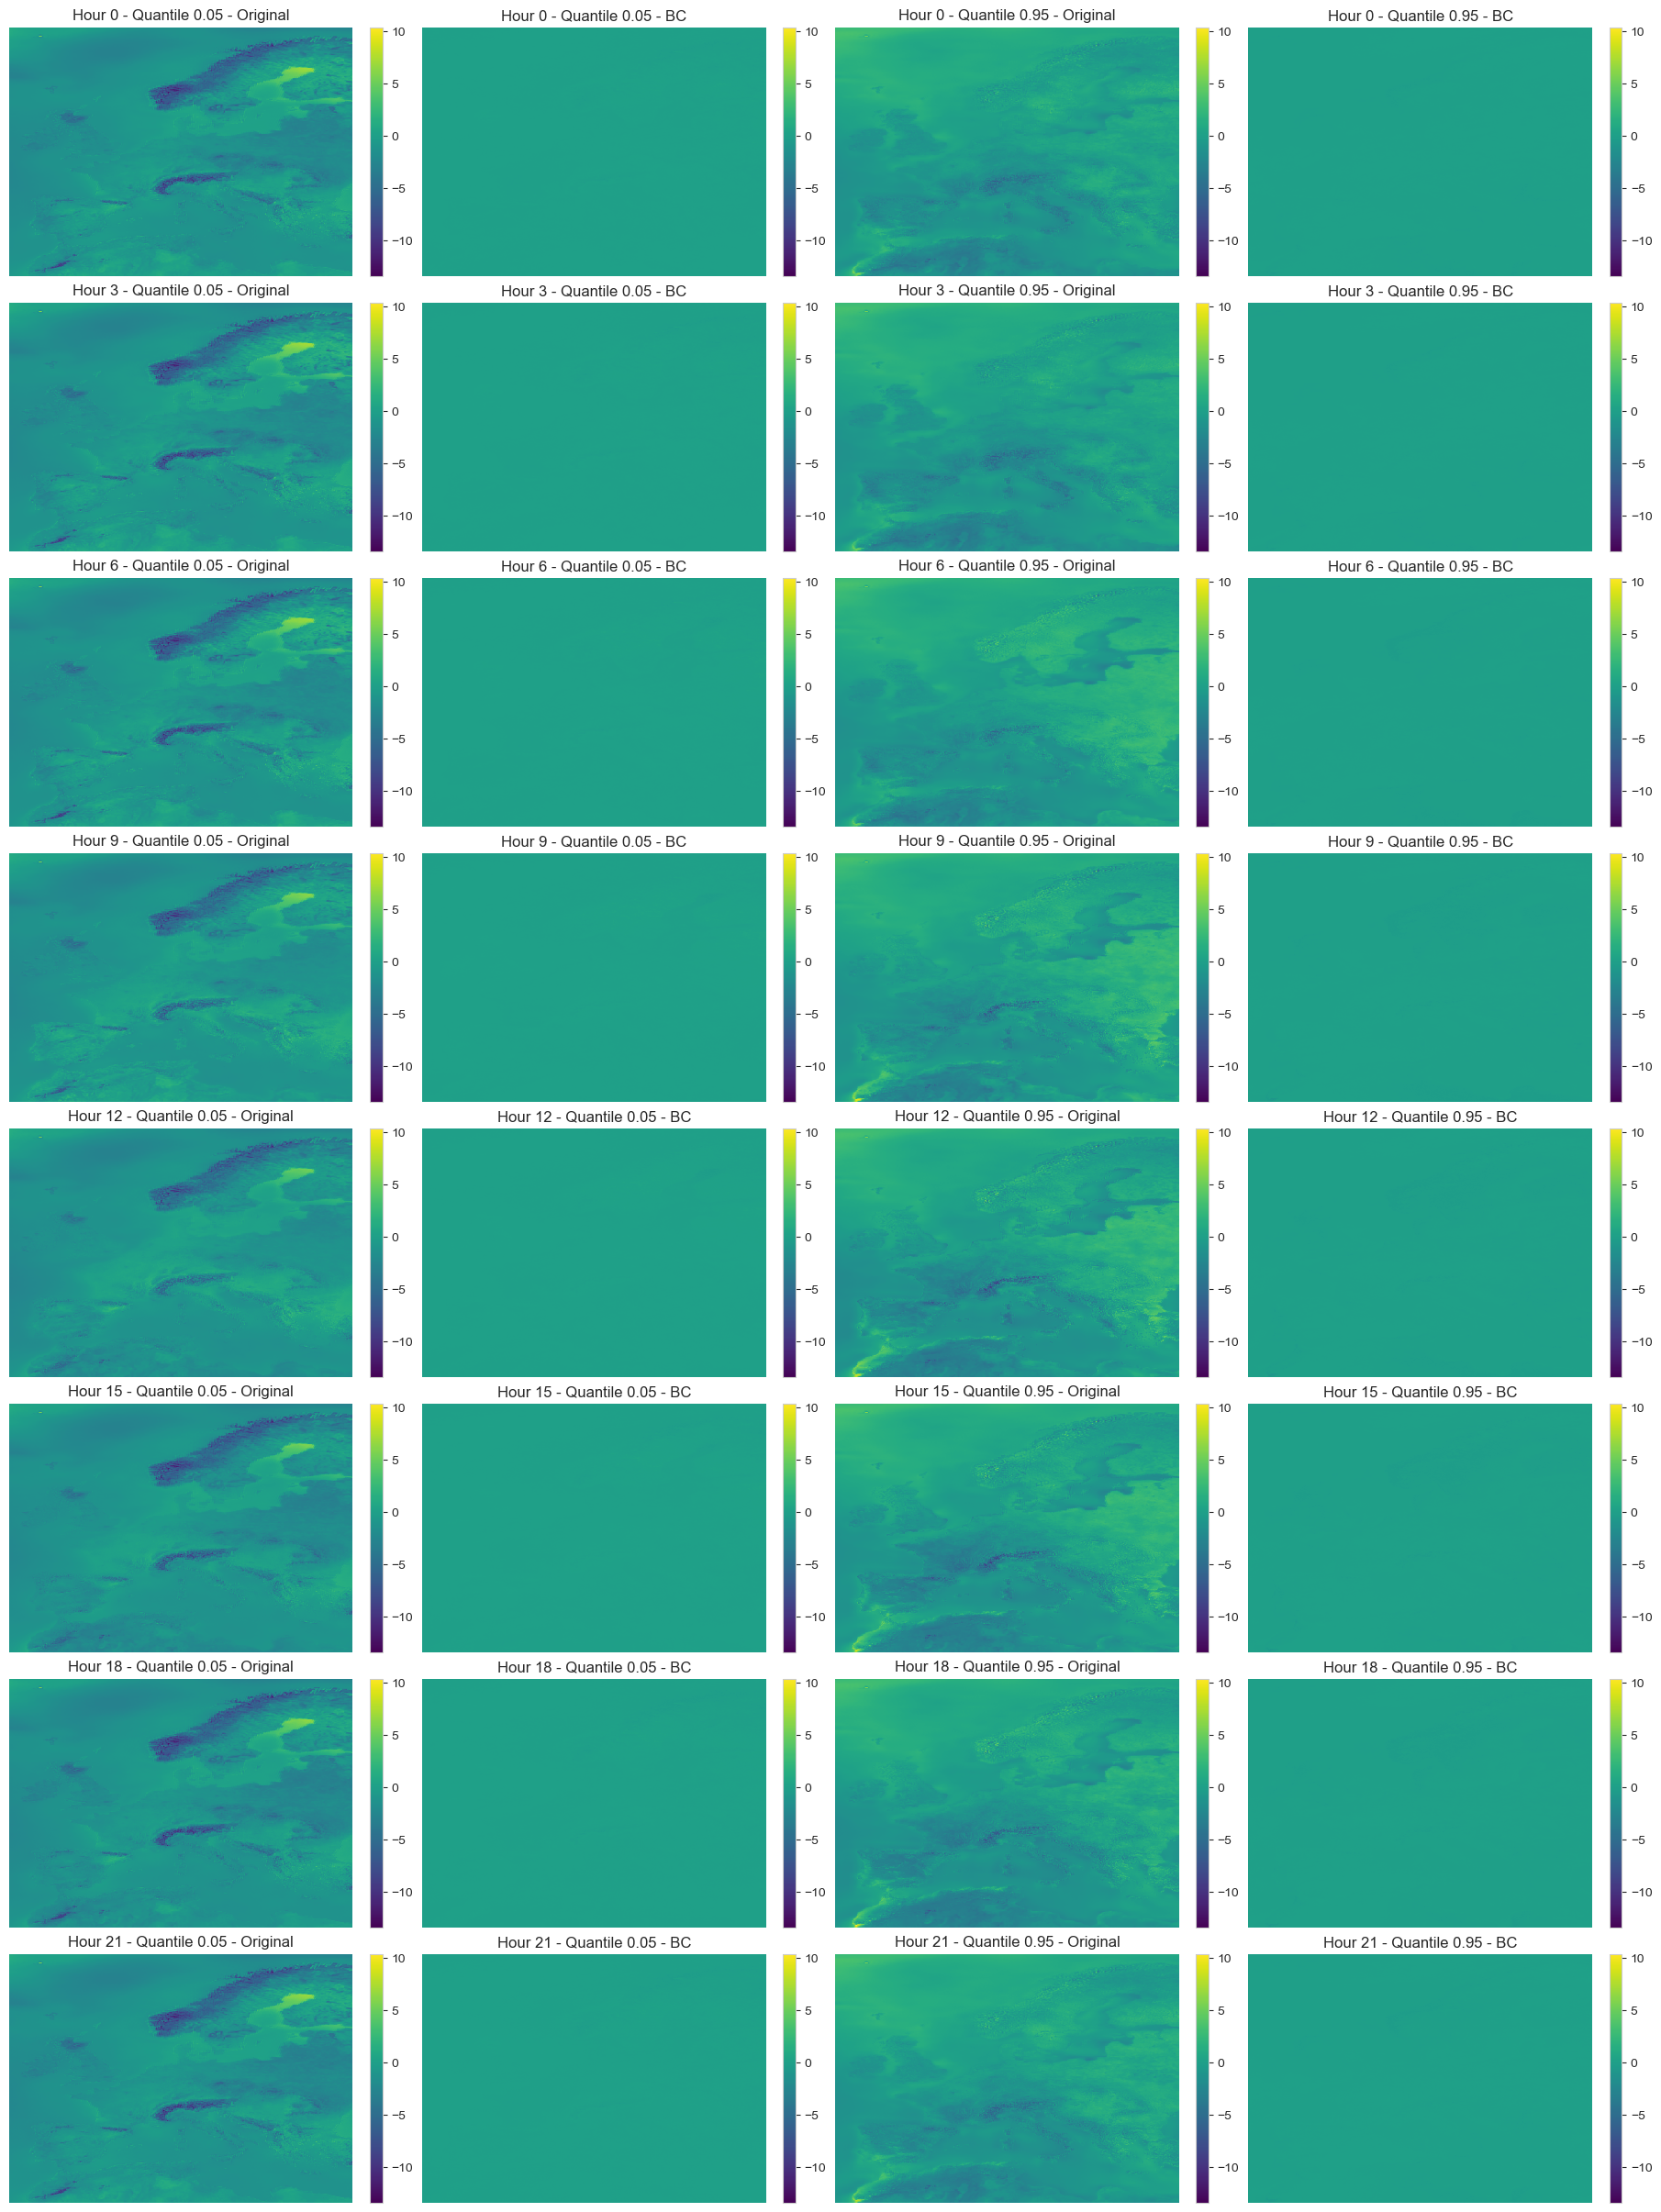

In [26]:
# Compute the overall min and max over all the datasets
overall_min = float("inf")
overall_max = float("-inf")

fig, axs = plt.subplots(8, 4, figsize=(18, 24), layout="constrained")

list_bias_quantile = []
list_bias_quantile_bc = []

for i, hour in enumerate(get_valid_hours(time_res, first_time_step.hour)):
    ds_hourly_quantile = xr.open_dataset(
        stats_tas_path / f"reference_quantiles_hour_{hour}.nc"
    )
    bias_quantile, bias_quantile_bc = validation.compute_bias(
        ds_hourly_quantile["climate_model_data"],
        ds_hourly_quantile["climate_model_data_bc"],
        ds_hourly_quantile["reanalysis_data"],
        hour=None,
        group=None,
        period=None,
    )
    overall_min = min(
        overall_min, bias_quantile.min().values, bias_quantile_bc.min().values
    )
    overall_max = max(
        overall_max, bias_quantile.max().values, bias_quantile_bc.max().values
    )
    list_bias_quantile.append(bias_quantile)
    list_bias_quantile_bc.append(bias_quantile_bc)

for i, hour in enumerate(get_valid_hours(time_res, first_time_step.hour)):
    bias_quantile = list_bias_quantile[i]
    bias_quantile_bc = list_bias_quantile_bc[i]
    quantiles = bias_quantile["quantile"].values

    for j, quant in enumerate(quantiles):
        bias_quantile.sel(quantile=quant).plot(
            ax=axs[i][j * 2],
            vmin=overall_min,
            vmax=overall_max,
            add_colorbar=True,
            label=f"Bias Climate Model - CERRA",
        )
        bias_quantile_bc.sel(quantile=quant).plot(
            ax=axs[i][j * 2 + 1],
            vmin=overall_min,
            vmax=overall_max,
            add_colorbar=True,
            label=f"Bias Climate Model Bias-Corrected - CERRA",
        )
        axs[i][j * 2].set_title(f"Hour {hour} - Quantile {quant} - Original")
        axs[i][j * 2 + 1].set_title(f"Hour {hour} - Quantile {quant} - BC")

axs = axs.flatten()
for ax in axs:
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.axis("off")


# fig.colorbar(axs[0].collections[0], ax=axs, orientation='vertical', fraction=0.02, pad=0.04)
plt.show()

In [ ]:
yearly_mean_trends = []
ds_yearly_mean = xr.open_dataset(stats_tas_path / "yearly_spatial_mean.nc")
yearly_mean_trends.append(
    validation.compute_trend(
        ds_yearly_mean["climate_model_data_mean"],
        ds_yearly_mean["climate_model_data_bc_mean"],
        ds_yearly_mean["reanalysis_data_mean"],
        hour=None,
        dim="year",
    )
)
yearly_mean_trends[-1]["selection"] = "total"

for hour in get_valid_hours(time_res, first_time_step.hour):
    ds_hourly_mean = xr.open_dataset(
        stats_tas_path / f"yearly_spatial_mean_hour_{hour}.nc"
    )
    yearly_mean_trends.append(
        validation.compute_trend(
            ds_hourly_mean["climate_model_data_mean"],
            ds_hourly_mean["climate_model_data_bc_mean"],
            ds_hourly_mean["reanalysis_data_mean"],
            hour=hour,
            dim="year",
        )
    )
    yearly_mean_trends[-1]["selection"] = f"hour_{hour}"

yearly_mean_trends = pd.concat(yearly_mean_trends, axis=0, ignore_index=True)